In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pl.Config.set_float_precision(4)
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(200)

SCHEME = "LL-SG"
RESULTS_DIR = Path("./results")

def _parse(name: str):
    parts = name.rsplit(".", 1)[0].split("_")
    shape = parts[0]
    nBackends = int(parts[1][1:])
    scheme_start = 2
    seed_idx = next(i for i, p in enumerate(parts) if p.startswith("s") and p[1:].isdigit())
    scheme = "_".join(parts[scheme_start:seed_idx])
    seed = int(parts[seed_idx][1:])
    return shape, nBackends, scheme, seed

def load_results(suffix: str) -> pl.DataFrame:
    dfs = []
    for f in RESULTS_DIR.iterdir():
        if not (f.is_file() and f.name.endswith(f"_{suffix}.csv")):
            continue
        shape, nBackends, scheme, seed = _parse(f.name)
        if scheme != SCHEME:
            continue
        df = pl.read_csv(str(f))
        df = df.with_columns(
            pl.lit(shape).alias("shape"),
            pl.lit(nBackends).alias("nBackends"),
            pl.lit(seed).alias("seed"),
        )
        dfs.append(df)
    return pl.concat(dfs) if dfs else pl.DataFrame()

## Analytical Reference Values

- GPU: RTX 5060 modelled with 5 DVFS operating points (runs at base OPP under LL-SG).
- Workload: YOLOv8n (8.7 GFLOP, 60 KB input, 1 KB output) per task.
- Topology: Point-to-point, 1 Gbps / 2 μs per link.
- DAG shapes: single (A), chain (A→B→C), fork-join (A→{B,C}→D).

In [2]:
PEAK_RATE = 19.2e12       # FP32 FLOPS
MIN_FREQ = 2.280e9        # Hz
MAX_FREQ = 2.50e9         # Hz
EFFICIENCY = 0.075
TRANSFER_BW = 32e9        # bytes/s

COMPUTE_DEMAND = 8.7e9    # FLOP
INPUT_SIZE = 60_000       # bytes 
OUTPUT_SIZE = 1_000       # bytes

RATE_AT_BASE = PEAK_RATE * (MIN_FREQ / MAX_FREQ)
EFF_RATE = RATE_AT_BASE * EFFICIENCY
T_PROC_MS = (INPUT_SIZE / TRANSFER_BW + COMPUTE_DEMAND / EFF_RATE + OUTPUT_SIZE / TRANSFER_BW) * 1e3

print(f"Effective rate:  {EFF_RATE:.4e} FLOPS")
print(f"Processing time: {T_PROC_MS:.4f} ms per task")

Effective rate:  1.3133e+12 FLOPS
Processing time: 6.6265 ms per task


In [3]:
tasks = load_results("tasks")
workload = load_results("workload")

## 1. Chain dependency ordering

Chain $A \to B \to C \to D$ on 1 backend: every successor dispatches only after its predecessor completes.

$$\text{dispatch}(v) \geq \text{complete}(u) \quad \forall\, u \to v$$

In [4]:
chain = tasks.filter((pl.col("shape") == "chain") & (pl.col("nBackends") == 1))
chain_wl = workload.filter((pl.col("shape") == "chain") & (pl.col("n_backends") == 1)) \
                   .select("seed", (pl.col("complete_ms") - pl.col("submit_ms")).alias("total_ms"))

per_seed = (
    chain.sort(["seed", "dag_idx"])
    .with_columns(
        pl.when(pl.col("dag_idx") == 0).then(pl.lit("A"))
        .when(pl.col("dag_idx") == 1).then(pl.lit("B"))
        .when(pl.col("dag_idx") == 2).then(pl.lit("C"))
        .when(pl.col("dag_idx") == 3).then(pl.lit("D"))
        .alias("label")
    )
    .pivot(values="dispatch_ms", index="seed", on="label", aggregate_function="first")
    .sort("seed")
    .with_columns(
        (pl.col("B") - pl.col("A")).alias("A\u2192B"),
        (pl.col("C") - pl.col("B")).alias("B\u2192C"),
        (pl.col("D") - pl.col("C")).alias("C\u2192D"),
    )
    .join(chain_wl, on="seed")
)
print(per_seed)

shape: (10, 9)
┌──────┬───────────┬───────────┬───────────┬───────────┬────────┬────────┬────────┬──────────┐
│ seed ┆ A         ┆ B         ┆ C         ┆ D         ┆ A→B    ┆ B→C    ┆ C→D    ┆ total_ms │
│ ---  ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---    ┆ ---    ┆ ---    ┆ ---      │
│ i32  ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64    ┆ f64    ┆ f64    ┆ f64      │
╞══════╪═══════════╪═══════════╪═══════════╪═══════════╪════════╪════════╪════════╪══════════╡
│ 1    ┆ 1002.0098 ┆ 1009.1479 ┆ 1016.2860 ┆ 1023.4241 ┆ 7.1381 ┆ 7.1381 ┆ 7.1381 ┆ 30.5700  │
│ 7    ┆ 1002.0098 ┆ 1009.1479 ┆ 1016.2860 ┆ 1023.4241 ┆ 7.1381 ┆ 7.1381 ┆ 7.1381 ┆ 30.5700  │
│ 2    ┆ 1002.0098 ┆ 1009.1479 ┆ 1016.2860 ┆ 1023.4241 ┆ 7.1381 ┆ 7.1381 ┆ 7.1381 ┆ 30.5700  │
│ 8    ┆ 1002.0098 ┆ 1009.1479 ┆ 1016.2860 ┆ 1023.4241 ┆ 7.1381 ┆ 7.1381 ┆ 7.1381 ┆ 30.5700  │
│ 9    ┆ 1002.0098 ┆ 1009.1479 ┆ 1016.2860 ┆ 1023.4241 ┆ 7.1381 ┆ 7.1381 ┆ 7.1381 ┆ 30.5700  │
│ 4    ┆ 1002.0098 ┆ 1009.1479 ┆ 10

## 2. Fork-join on 1 backend
With only one backend available, $B$ and $C$ are dispatched simultaneously but must execute sequentially on the one backend. The $C\to D$ gap captures the queue wait: $\approx 2\,T_{\text{proc}}$ instead of $T_{\text{proc}}$.

In [5]:
fj1 = tasks.filter((pl.col("shape") == "forkjoin") & (pl.col("nBackends") == 1))
fj1_wl = workload.filter((pl.col("shape") == "forkjoin") & (pl.col("n_backends") == 1)) \
                  .select("seed", (pl.col("complete_ms") - pl.col("submit_ms")).alias("total_ms"))

per_seed = (
    fj1.sort(["seed", "dag_idx"])
    .with_columns(
        pl.when(pl.col("dag_idx") == 0).then(pl.lit("A"))
        .when(pl.col("dag_idx") == 1).then(pl.lit("B"))
        .when(pl.col("dag_idx") == 2).then(pl.lit("C"))
        .when(pl.col("dag_idx") == 3).then(pl.lit("D"))
        .alias("label")
    )
    .pivot(values="dispatch_ms", index="seed", on="label", aggregate_function="first")
    .sort("seed")
    .with_columns(
        (pl.col("B") - pl.col("A")).alias("A\u2192B"),
        (pl.col("C") - pl.col("A")).alias("A\u2192C"),
        (pl.col("D") - pl.col("C")).alias("C\u2192D"),
    )
    .join(fj1_wl, on="seed")
)
print(per_seed)

shape: (10, 9)
┌──────┬───────────┬───────────┬───────────┬───────────┬────────┬────────┬─────────┬──────────┐
│ seed ┆ A         ┆ B         ┆ C         ┆ D         ┆ A→B    ┆ A→C    ┆ C→D     ┆ total_ms │
│ ---  ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---    ┆ ---    ┆ ---     ┆ ---      │
│ i32  ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64    ┆ f64    ┆ f64     ┆ f64      │
╞══════╪═══════════╪═══════════╪═══════════╪═══════════╪════════╪════════╪═════════╪══════════╡
│ 4    ┆ 1002.0100 ┆ 1009.1481 ┆ 1009.1481 ┆ 1022.9188 ┆ 7.1381 ┆ 7.1381 ┆ 13.7707 ┆ 30.0700  │
│ 7    ┆ 1002.0100 ┆ 1009.1481 ┆ 1009.1481 ┆ 1022.9188 ┆ 7.1381 ┆ 7.1381 ┆ 13.7707 ┆ 30.0700  │
│ 1    ┆ 1002.0100 ┆ 1009.1481 ┆ 1009.1481 ┆ 1022.9188 ┆ 7.1381 ┆ 7.1381 ┆ 13.7707 ┆ 30.0700  │
│ 2    ┆ 1002.0100 ┆ 1009.1481 ┆ 1009.1481 ┆ 1022.9188 ┆ 7.1381 ┆ 7.1381 ┆ 13.7707 ┆ 30.0700  │
│ 5    ┆ 1002.0100 ┆ 1009.1481 ┆ 1009.1481 ┆ 1022.9188 ┆ 7.1381 ┆ 7.1381 ┆ 13.7707 ┆ 30.0700  │
│ 8    ┆ 1002.0100 ┆ 1009

## 3. Fork-join parallel dispatch
Fork-join $A \to \{B, C\} \to D$ on 2 backends: $B$ and $C$ dispatch simultaneously to distinct backends.

In [6]:
fj2 = tasks.filter((pl.col("shape") == "forkjoin") & (pl.col("nBackends") == 2))
fj2_wl = workload.filter((pl.col("shape") == "forkjoin") & (pl.col("n_backends") == 2)) \
                  .select("seed", (pl.col("complete_ms") - pl.col("submit_ms")).alias("total_ms"))

b = fj2.filter(pl.col("dag_idx") == 1).select(
    "seed",
    pl.col("dispatch_ms").alias("b_dispatch_ms"),
    pl.col("backend_idx").alias("b_backend"),
)
c = fj2.filter(pl.col("dag_idx") == 2).select(
    "seed",
    pl.col("dispatch_ms").alias("c_dispatch_ms"),
    pl.col("backend_idx").alias("c_backend"),
)

parallel = (
    b.join(c, on="seed")
    .with_columns(
        (pl.col("b_dispatch_ms") - pl.col("c_dispatch_ms")).abs().alias("dispatch_diff_ms"),
    )
    .join(fj2_wl, on="seed")
    .sort("seed")
)
print(parallel)

assert parallel["dispatch_diff_ms"].max() < 0.01, "B and C should dispatch simultaneously"
assert (parallel["b_backend"] != parallel["c_backend"]).all(), \
    "B and C should be on distinct backends"
print("\nB and C dispatch simultaneously on distinct backends across all seeds.")

shape: (10, 7)
┌──────┬───────────────┬───────────┬───────────────┬───────────┬──────────────────┬──────────┐
│ seed ┆ b_dispatch_ms ┆ b_backend ┆ c_dispatch_ms ┆ c_backend ┆ dispatch_diff_ms ┆ total_ms │
│ ---  ┆ ---           ┆ ---       ┆ ---           ┆ ---       ┆ ---              ┆ ---      │
│ i32  ┆ f64           ┆ i64       ┆ f64           ┆ i64       ┆ f64              ┆ f64      │
╞══════╪═══════════════╪═══════════╪═══════════════╪═══════════╪══════════════════╪══════════╡
│ 1    ┆ 1009.1481     ┆ 0         ┆ 1009.1481     ┆ 1         ┆ 0.0000           ┆ 23.4400  │
│ 2    ┆ 1009.1481     ┆ 0         ┆ 1009.1481     ┆ 1         ┆ 0.0000           ┆ 23.4400  │
│ 3    ┆ 1009.1481     ┆ 0         ┆ 1009.1481     ┆ 1         ┆ 0.0000           ┆ 23.4400  │
│ 4    ┆ 1009.1481     ┆ 0         ┆ 1009.1481     ┆ 1         ┆ 0.0000           ┆ 23.4400  │
│ 5    ┆ 1009.1481     ┆ 0         ┆ 1009.1481     ┆ 1         ┆ 0.0000           ┆ 23.4400  │
│ 6    ┆ 1009.1481     ┆ 0         

## Gantt timelines

Visual contrast between parallel execution (fork-join on 2 backends) and capacity-bound serialisation (fork-join on 1 backend).

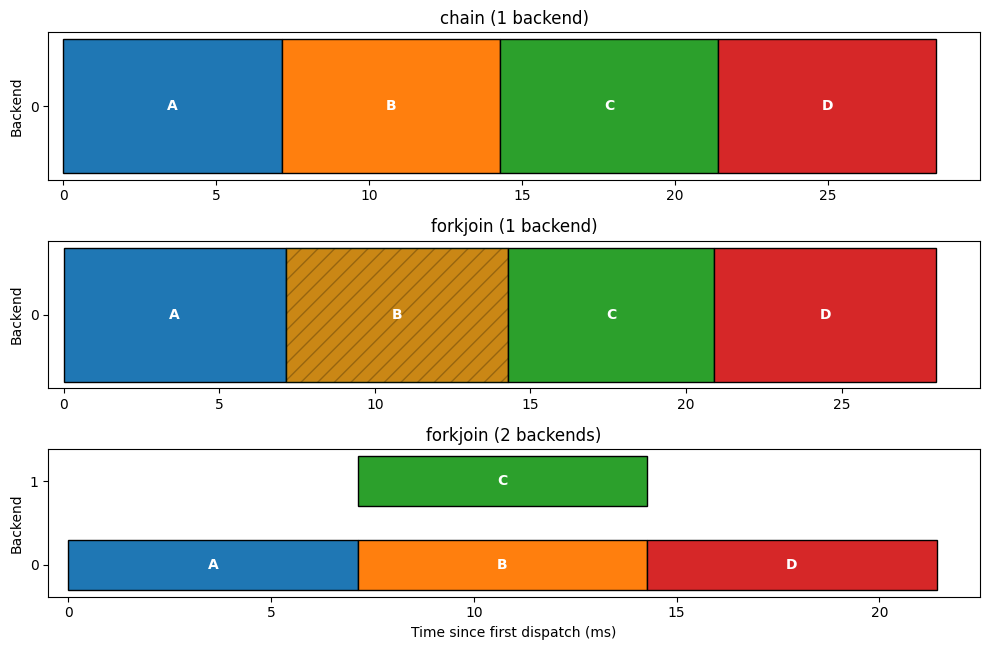

In [7]:
configs = [("chain", 1), ("forkjoin", 1), ("forkjoin", 2)]
labels = ["A", "B", "C", "D"]
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

fig, axes = plt.subplots(len(configs), 1, figsize=(10, 2.2 * len(configs)))

for ax, (shape, nB) in zip(axes, configs):
    subset = tasks.filter(
        (pl.col("shape") == shape)
        & (pl.col("nBackends") == nB)
        & (pl.col("seed") == 1)
    ).sort("dag_idx")
    if len(subset) == 0:
        continue
    t0 = subset["dispatch_ms"].min()
    backend_last_complete = {}
    rows = []
    for i, row in enumerate(subset.iter_rows(named=True)):
        bkd = row["backend_idx"]
        dispatch = row["dispatch_ms"]
        complete = row["complete_ms"]
        eff_start = max(dispatch, backend_last_complete.get(bkd, dispatch))
        backend_last_complete[bkd] = complete
        rows.append((i, bkd, dispatch, eff_start, complete))

    for i, bkd, dispatch, eff_start, complete in rows:
        if eff_start > dispatch:
            ax.barh(bkd, eff_start - dispatch, left=dispatch - t0, color=colors[i],
                    alpha=0.25, edgecolor="black", hatch="//", height=0.6)
        ax.barh(bkd, complete - eff_start, left=eff_start - t0, color=colors[i],
                edgecolor="black", height=0.6)
        ax.text(eff_start - t0 + (complete - eff_start) / 2, bkd, labels[i],
                ha="center", va="center", color="white", fontweight="bold")

    ax.set_ylabel("Backend")
    ax.set_title(f"{shape} ({nB} backend{'s' if nB > 1 else ''})")
    ax.set_yticks(range(nB))
    ax.set_xlim(left=-0.5)

axes[-1].set_xlabel("Time since first dispatch (ms)")
fig.tight_layout()
plt.show()